<a href="https://colab.research.google.com/github/hyui02/ESAA_assignment/blob/main/ESAA_WEEK12_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np


data_url = "http://lib.stat.cmu.edu/datasets/boston"

raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)

data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])

target = raw_df.values[1::2, 2]

#Column names for the Boston dataset

feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

X_data = pd.DataFrame(data, columns=feature_names)

y_target = pd.Series(target, name='PRICE')

##6 규제 선형 모델- 릿지, 라쏘, 엘라스틱넷
### 릿지 회귀
릿지 클래스의 주요 생성 파라미터는 alpha

In [2]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

#alpha=10으로 설정해 릿지 회귀 수행
ridge = Ridge(alpha=10)
neg_mse_scores = cross_val_score(ridge, X_data, y_target
                                  , scoring="neg_mean_squared_error", cv=5)
rmse_scores = np.sqrt(-1*neg_mse_scores)
avg_rmse = np.mean(rmse_scores)
print('5 folds의 개별 Negative MSE scores: ', np.round(neg_mse_scores, 3))
print('5 folds의 개별 RMSE scores : ', np.round(rmse_scores, 3))
print('5 folds의 평균 RMSE :{0:.3f} '.format(avg_rmse))

5 folds의 개별 Negative MSE scores:  [-11.422 -24.294 -28.144 -74.599 -28.517]
5 folds의 개별 RMSE scores :  [3.38  4.929 5.305 8.637 5.34 ]
5 folds의 평균 RMSE :5.518 


In [3]:
#릿지에 사용될 alpha 파라미터의 값을 정의
alphas=[0,0.1,1,10,100]

#alphas list 값을 반복하면서 alpha 에 따른 평균 rmse를 구함
for alpha in alphas:
  ridge= Ridge(alpha=alpha)

  #cross_val_score를 이용해 5 폴드의 평균 rmse를 계산
  neg_mse_scores= cross_val_score(ridge,X_data,y_target,
                                  scoring="neg_mean_squared_error",cv=5)
  avg_rmse= np.mean(np.sqrt(-1*neg_mse_scores))
  print('alpha {0}일 때 5 folds의 평균 RMSE: {1:.3f}'.format(alpha,avg_rmse))

alpha 0일 때 5 folds의 평균 RMSE: 5.829
alpha 0.1일 때 5 folds의 평균 RMSE: 5.788
alpha 1일 때 5 folds의 평균 RMSE: 5.653
alpha 10일 때 5 folds의 평균 RMSE: 5.518
alpha 100일 때 5 folds의 평균 RMSE: 5.330


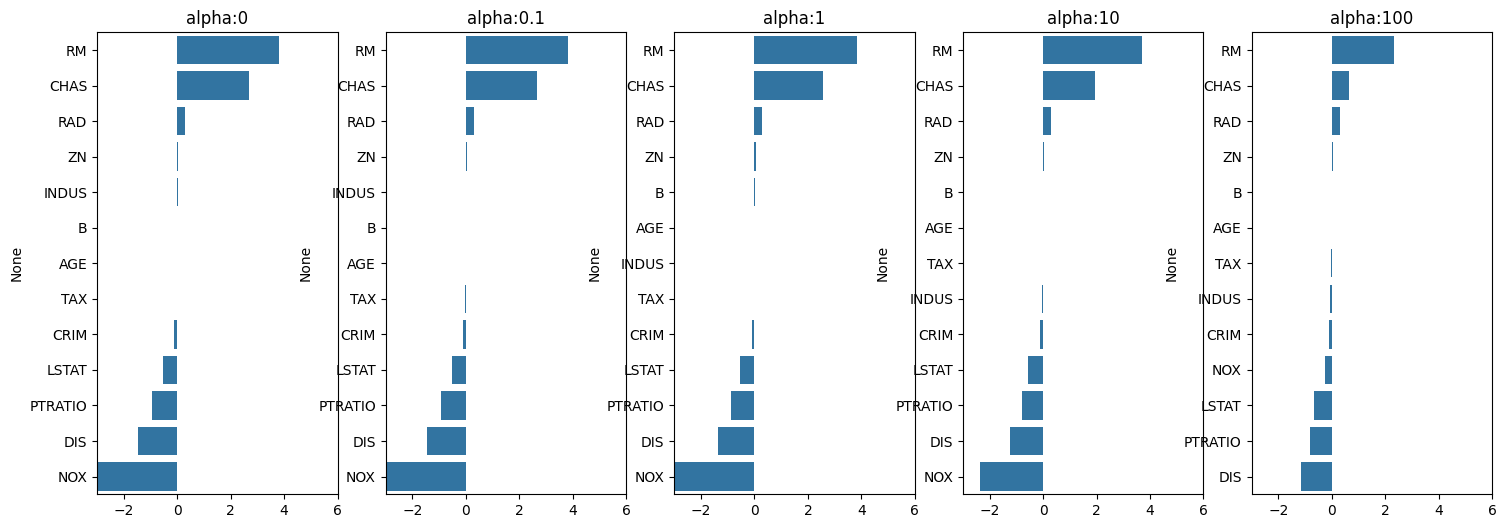

In [4]:
import matplotlib.pyplot as plt

import seaborn as sns
#각 alpha에따른 회귀 계수 값을 시각화하기 위해 5개의 열로 된 맷플롯립 축 생성
fig,axs= plt.subplots(figsize=(18,6),nrows=1, ncols=5)
#각 alpha에 따른 회귀 계수 값을 데이터로 저장하기 위한 dataframe 생성
coeff_df= pd.DataFrame()

#alphas 리스트 값을 차례로 입력해 회귀 계수 값 시각화 및 데이터 저장. pos는 axis의 위치 지정
for pos, alpha in enumerate(alphas):
  ridge= Ridge(alpha=alpha)
  ridge.fit(X_data,y_target)
  #alpha에 따른 피처별로 회귀 계수를 Series로 변환하고 이를 Dataframe의 칼럼으로 추가
  coeff=pd.Series(data=ridge.coef_,index=X_data.columns)
  colname='alpha:'+str(alpha)
  coeff_df[colname]=coeff
  #막대 그래프로 각 alpha 값에서의 회귀 계수를 시각화. 회귀 계수값이 높은 순으로 표현
  coeff=coeff.sort_values(ascending=False)
  axs[pos].set_title(colname)
  axs[pos].set_xlim(-3,6)
  sns.barplot(x=coeff.values,y=coeff.index,ax=axs[pos])

#for 문 바깥에서 맷플롯립의 show 호출 및 alpha에 따른 피처별 회귀 계수를 회귀 계수를 DataFrame으로 표시
plt.show()

In [5]:
ridge_alphas=[0,0.1,1,10,100]
sort_column='alpha:'+str(ridge_alphas[0])
coeff_df.sort_values(by=sort_column,ascending=False)

,alpha:0,alpha:0.1,alpha:1,alpha:10,alpha:100
RM,3.809865,3.818233,3.854000,3.702272,2.334536
CHAS,2.686734,2.670019,2.552393,1.952021,0.638335
RAD,0.306049,0.303515,0.290142,0.279596,0.315358
ZN,0.046420,0.046572,0.047443,0.049579,0.054496
INDUS,0.020559,0.015999,-0.008805,-0.042962,-0.052826
B,0.009312,0.009368,0.009673,0.010037,0.009393
AGE,0.000692,-0.000269,-0.005415,-0.010707,0.001212
TAX,-0.012335,-0.012421,-0.012912,-0.013993,-0.015856
CRIM,-0.108011,-0.107474,-0.104595,-0.101435,-0.102202
LSTAT,-0.524758,-0.525966,-0.533343,-0.559366,-0.660764


- alpha 값을 계속 증가시킬수록 회귀 계수 값은 지속적으로 작아진다


##라쏘 회귀
- W의 절댓값에 페널티를 부여하는 L1 규제를 선형 회귀에 적용한 것
- L1 규제:alpha*||W||1 -> 불필요한 회귀 계수를 급격하게 감소시켜 0으로 만들고 제거
- 목표: RSS(W)+ alpha*||W||1 을 최소화하는 W를 찾는것

In [6]:
from sklearn.linear_model import Lasso, ElasticNet

#alpha값에 따른 회귀 모델의 폴드 평균 RMSE를 출력하고 회귀 계수값들을 DataFrame으로 반환
def get_linear_reg_eval(model_name,params=None,X_data_n=None,y_target_n=None,
                        verbose=True, return_coeff=True):
  coeff_df=pd.DataFrame()
  if verbose: print('######', model_name,'######')
  for param in params:
    if model_name=='Ridge': model=Ridge(alpha=param)
    elif model_name=='Lasso': model=Lasso(alpha=param)
    elif model_name=='ElasticNet': model=ElasticNet(alpha=param,l1_ratio=0.7)
    neg_mse_scores= cross_val_score(model,X_data_n,y_target_n,
                                    scoring="neg_mean_squared_error",cv=5)
    avg_rmse=np.mean(np.sqrt(-1*neg_mse_scores))
    print('alpha {0}일 때 5 folds의 평균 RMSE: {1:.3f}'.format(param,avg_rmse))
    #cross_val_score는 evaluation metric만 반환하므로 모델을 다시 학습하여 회귀 계수 추출

    model.fit(X_data_n,y_target_n)
    if return_coeff:
      #alpha에 따른 피처별 회귀 계수를 Series로 변환하고 이를 DataFrame의 칼럼으로 추가
      coeff=pd.Series(data=model.coef_,index=X_data_n.columns)
      colname='alpha:'+str(param)
      coeff_df[colname]=coeff


    return coeff_df

#end of get_linear_regre_eval

In [7]:
#라쏘에 사용될 alpha 파라미터의 값을 정의하고 get_linear_reg_eval() 함수 호출
lasso_alphas=[0.07,0.1,0.5,1,3]
coeff_lasso_df=get_linear_reg_eval('Lasso',params=lasso_alphas,X_data_n=X_data,y_target_n=y_target)

###### Lasso ######
alpha 0.07일 때 5 folds의 평균 RMSE: 5.612


In [8]:
#반환된 coeff_lasso_df를 첫번쨰 컬럼순으로 내림차순 정렬해 회귀계수 DataFrame 출력
sort_column='alpha:'+str(lasso_alphas[0])
coeff_lasso_df.sort_values(by=sort_column,ascending=False)

,alpha:0.07
RM,3.789725
CHAS,1.434343
RAD,0.270936
ZN,0.049059
B,0.010248
NOX,-0.000000
AGE,-0.011706
TAX,-0.014290
INDUS,-0.042120
CRIM,-0.098193


- alpha 값에 따른 피처별 회귀 계수

## 엘라스틱넷 회귀
- L2규제와 L1 규제를 결합한 회귀
- RSS(W)+ alpha2*||W||22+ alpha1*||W||1 식을 최소화하는 W를 찾는 것


In [9]:
# 엘라스틱넷에 사용될 alpha 파라미터의 값들을 정의하고 get_libear_reg_eval() 함수 호출
#l1_ratio는 0.7로 고정
elastic_alphas=[0.07,0.1,0.5,1,3]
coeff_elastic_df=get_linear_reg_eval('ElasticNet',params=elastic_alphas, X_data_n=X_data,y_target_n=y_target)

###### ElasticNet ######
alpha 0.07일 때 5 folds의 평균 RMSE: 5.542


In [10]:
#반환된 coeff_elastic_df를 첫번째 컬럼순으로 내림차순 정렬해 회귀계수 dataframe 출력
sort_column='alpha:'+str(elastic_alphas[0])
coeff_elastic_df.sort_values(by=sort_column,ascending=False)

,alpha:0.07
RM,3.574162
CHAS,1.330724
RAD,0.278880
ZN,0.050107
B,0.010122
AGE,-0.010116
TAX,-0.014522
INDUS,-0.044855
CRIM,-0.099468
NOX,-0.175072


## 선형 회귀 모델을 위한 데이터 변환
- 일반적으로 피처와 타깃값 간에 선형의 관계가 있다고 가정하고 이러한 최적의 선형함수를 찾아내 결괏값을 예측
- 피처값과 타깃값의 분포가 정규분포 형태를 매우 선호
- 특히 타깃값이 정규분포가 아니라 특정값의 분포가 치우친 왜곡(Skew)된 형태이면 예측 성능에 부정적인 영향
- 피처값 역시 결정값보다는 덜하지만 왜곡된 분포도로 인해 예측 성능에 부정적인 영향을 미칠 수 있음
- 따라서 선형 회귀 모델을 적용하기 전에 먼저 데이터에 대한 스케일링/정규화 작업을 수행하는 것이 일반적
- 단, 스케일링/정규화 작업을 선행한다고 무조건 예측 성능이 향상되는 것은 아님 -> 중요 피처들이나 타깃값의 분포도가 심하게 왜곡됐을 경우에 변환 작업 수행

### 피처 데이터 세트에 적용하는 변환 작업
1. StandardScaler로 평균 0, 분산 1인 표준 정규 분포를 가진 데이터 세트로 변환하거나 MinMaxScaler로 최솟값 0, 최댓값 1인 값으로 정규화
2. 스케일링/정규화를 수행한 데이터 세트에 다시 다항 특성을 적용하여 변환 -> 1번 방법을 통해 예측 성능에 향상이 없을 경우 적용
3. 원래 값에 log 함수를 적용하면 보다 정규 분포에 가까운 형태로 값이 분포됨 -> 로그 변환(Log Transformation)

- 실제로 선형 회귀에서는 1, 2번보다 로그 변환이 훨씬 많이 사용됨
- 1번 방법은 예측 성능 향상을 크게 기대하기 어려운 경우가 많고, 2번 방법은 피처의 개수가 매우 많을 경우 다항 변환으로 생성되는 피처의 개수가 기하급수로 늘어나서 과적합의 이슈가 발생할 수 있음

### 타깃값 변환
- 타깃값의 경우 일반적으로 로그 변환을 적용
- 결정값을 정규 분포나 다른 정규값으로 변환하면 변환된 값을 다시 원본 타깃값으로 원복하기 어려울 수 있음
- 왜곡된 분포도 형태의 타깃값을 로그 변환하여 예측 성능 향상이 된 경우가 많은 사례에서 검증됨
- 로그 변환 시 np.log()가 아닌 np.log1p() 사용 -> 1+log() 함수를 적용해서 언더플로우 발생을 방지

In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures

#method는 표준 정규 분포 변환, 최댓값/최솟값 정규화, 로그변환 결정
#p_degree는 다항식특성을 추가할 때 적용, p_degree는 2 이상 부여하지 않음
def get_scaled_data(method='None',p_degree=None,input_data=None):
  if method == 'Standard':
    scaled_data=StandardScaler().fit_transform(input_data)
  elif method == 'MinMax':
    scaled_data=MinMaxScaler().fit_transform(input_data)
  elif method == 'Log':
    scaled_data=np.log1p(input_data)
  else:
    scaled_data=input_data

  if p_degree != None:
    scaled_data= PolynomialFeatures(degree=p_degree,include_bias=False).fit_transform(scaled_data)

  return scaled_data

- get_scaled_data(): method 인자로 표준 정규 분포 변환(Standard), 최댓값/최솟값 정규화(MinMax), 로그 변환(Log)을 결정하고 p_degree 인자로 다항식 특성을 추가할 때 다항식 차수를 입력받음
- 피처 개수가 많아지면 다항식 특성을 추가할 때 피처 개수가 너무 많아지므로 p_degree는 2 이상 부여하지 않음
- 릿지 회귀의 alpha 값을 변화시키면서 피처 데이터 세트를 여러 가지 방법으로 변환한 데이터 세트를 입력받을 경우 RMSE 값이 어떻게 변하는지 확인

In [12]:
#ridge의 alpha 값을 다르게 적용하고 다양한 데이터 변환 방법에 따른 RMSE 추출
alphas=[0.1,1,10,100]

#5개 방식으로 변환 먼저 원본 그대로, 표준정규 분포, 표준정규 분포+다항식 특성
#최대/최소 정규화, 최대/최소 정규화+다항식특성, 로그 변환
scale_methods=[(None,None),('Standard',None),('Standard',2),('MinMax',None),('MinMax',2),('Log',None)]
for scale_methods in scale_methods:
  X_data_scaled=get_scaled_data(method=scale_methods[0],p_degree=scale_methods[1],input_data=X_data)
  print('\n##변환 유형:{0}, Polynomial Degree:{1}'.format(scale_methods[0],scale_methods[1]))
  get_linear_reg_eval('Ridge',params=alphas,X_data_n=X_data_scaled,y_target_n=y_target,
                      verbose=False,return_coeff=False)


##변환 유형:None, Polynomial Degree:None
alpha 0.1일 때 5 folds의 평균 RMSE: 5.788

##변환 유형:Standard, Polynomial Degree:None
alpha 0.1일 때 5 folds의 평균 RMSE: 5.826

##변환 유형:Standard, Polynomial Degree:2
alpha 0.1일 때 5 folds의 평균 RMSE: 8.827

##변환 유형:MinMax, Polynomial Degree:None
alpha 0.1일 때 5 folds의 평균 RMSE: 5.764

##변환 유형:MinMax, Polynomial Degree:2
alpha 0.1일 때 5 folds의 평균 RMSE: 5.298

##변환 유형:Log, Polynomial Degree:None
alpha 0.1일 때 5 folds의 평균 RMSE: 4.770


## 7 로지스틱 회귀
- 선형 회귀 방식을 분류에 적용한 알고리즘 -> 로지스틱 회귀는 분류에 사용됨
- 로지스틱 회귀 역시 선형 회귀 계열
- 회귀가 선형인가 비선형인가는 독립변수가 아닌 가중치 변수가 선형인지 아닌지를 따름
- 선형 회귀와 다른 점: 학습을 통해 선형 함수의 회귀 최적선을 찾는 것이 아니라 시그모이드(Sigmoid) 함수 최적선을 찾고 이 시그모이드 함수의 반환 값을 확률로 간주해 확률에 따라 분류를 결정

### 시그모이드 함수
- y = 1 / (1 + e^-x)
- x 값이 +, -로 아무리 커지거나 작아져도 y 값은 항상 0과 1 사이 값을 반환
- x 값이 커지면 1에 근사하며 x 값이 작아지면 0에 근사, x가 0일 때는 0.5

### 로지스틱 회귀 예측 방식
- 예) 종양의 크기(X축)에 따라 악성 종양인지(1) 그렇지 않은지(0)를 분류
- 선형 회귀 라인으로는 0과 1을 제대로 분류하지 못함 -> 시그모이드 함수를 이용하면 좀 더 정확하게 0과 1에 대해 분류 가능
- 선형 회귀 식 y = w1x + w0에서 확률 p를 직접 예측하기 위해 오즈비(Odds Ratio) 사용
- Odds(p) = p / (1 - p), 여기에 로그를 취하면 Log(Odds(p)) = w1x + w0
- 이를 p(x)에 대해 정리하면 p(x) = 1 / (1 + e^-(w1x + w0))
- 로지스틱 회귀는 학습을 통해 시그모이드 함수의 w를 최적화하여 예측하는 것

### 로지스틱 회귀 특징
- 가볍고 빠르지만 이진 분류 예측 성능도 뛰어남 -> 이진 분류의 기본 모델로 사용하는 경우가 많음
- 희소한 데이터 세트 분류에도 뛰어난 성능 -> 텍스트 분류에서도 자주 사용됨

### 사이킷런 LogisticRegression 클래스
- solver 파라미터: 'lbfgs', 'liblinear', 'newton-cg', 'sag', 'saga' 값을 적용해서 최적화를 선택
- lbfgs: 사이킷런 버전 0.22부터 solver의 기본 설정값, 메모리 공간을 절약할 수 있고 CPU 코어 수가 많다면 최적화를 병렬로 수행 가능
- liblinear: 사이킷런 버전 0.21까지 solver의 기본 설정값, 다차원이고 작은 데이터 세트에서 효과적으로 동작하지만 국소 최적화(Local Minimum)에 이슈가 있고 병렬로 최적화할 수 없음
- newton-cg: 좀 더 정교한 최적화가 가능하지만 대용량의 데이터에서 속도가 많이 느려짐
- sag: Stochastic Average Gradient로서 경사 하강법 기반의 최적화를 적용, 대용량의 데이터에서 빠르게 최적화
- saga: sag와 유사한 최적화 방식이며 L1 정규화를 가능하게 해줌

### 위스콘신 유방암 데이터 세트로 암 여부 판단
- 선형 회귀 계열의 로지스틱 회귀는 데이터의 정규 분포도에 따라 예측 성능 영향을 받을 수 있음
- 데이터에 먼저 정규 분포 형태의 표준 스케일링을 적용한 뒤에 학습/테스트 데이터 세트로 분리

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

cancer=load_breast_cancer()

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

#StrandardScaler()로 평균이 0, 분산 1로 데이터 분포도 변환
scaler=StandardScaler()
data_scaled=scaler.fit_transform(cancer.data)

X_train,X_test,y_train,y_test=train_test_split(data_scaled,cancer.target,test_size=0.3,random_state=0)


In [15]:
from sklearn.metrics import accuracy_score, roc_auc_score


#로지스틱 회귀를 이용하여 학습및 예측 수행
#solver 인자값을 생성자로 압력하지 않으면 solver='lbfgs'
lr_clf = LogisticRegression()
lr_clf.fit(X_train, y_train) # 추가
lr_preds = lr_clf.predict(X_test)
lr_preds_proba = lr_clf.predict_proba(X_test)[:, 1]

#accuracy와 roc_auc 측정
print('{0:.3f},{1:.3f}'.format(accuracy_score(y_test, lr_preds),

roc_auc_score(y_test, lr_preds_proba)))

0.977,0.995


In [16]:
solvers=['lbfgs','liblinear','newton-cg','sag','saga']

#여러 개의 solver 값별로 logisticRegression 학습 후 성능 평가
for solver in solvers:
  lr_clf=LogisticRegression(solver=solver, max_iter=600)
  lr_clf.fit(X_train,y_train)
  lr_preds=lr_clf.predict(X_test)
  lr_preds_proba=lr_clf.predict_proba(X_test)[:,1]

  #accuracy와 roc_auc 측정
  print('solver;{0}, accuracy:{1:.3f},roc_auc{2:.3f}'.
        format(solver,accuracy_score(y_test,lr_preds), roc_auc_score(y_test,lr_preds_proba)))

solver;lbfgs, accuracy:0.977,roc_auc0.995
solver;liblinear, accuracy:0.982,roc_auc0.995
solver;newton-cg, accuracy:0.977,roc_auc0.995
solver;sag, accuracy:0.982,roc_auc0.995
solver;saga, accuracy:0.982,roc_auc0.995


- solver 값별로 성능 결과가 약간씩 차이가 있지만 데이터 세트가 작아서 큰 차이가 없음
- 일반적으로 solver 값에 따른 성능 차이는 크지 않음
- max_iter: solver로 sag, saga를 적용할 때 최적화를 위한 최대 반복 횟수, 기본값은 100 -> 반복 횟수가 부족하면 수렴하지 않았다는 경고 메시지가 나옴

### 주요 하이퍼 파라미터
- penalty: 규제(Regularization)의 유형을 설정하며 'l2'로 설정 시 L2 규제, 'l1'으로 설정 시 L1 규제, 기본은 'l2'
- C: 규제 강도를 조절하는 alpha 값의 역수 -> C = 1/alpha, C 값이 작을수록 규제 강도가 큼
- L1, L2 규제의 경우 solver 설정에 따라 영향을 받음
- liblinear, saga는 L1, L2 규제가 모두 가능하지만 lbfgs, newton-cg, sag는 L2 규제만 가능

In [17]:
from sklearn.model_selection import GridSearchCV

params={'solver':['liblinear','lbfgs'],'penalty':['l2','l1'],'C':[0.01,0.1,1,5,10]}

lr_clf=LogisticRegression()

grid_clf=GridSearchCV(lr_clf,param_grid=params,scoring='accuracy',cv=3)
grid_clf.fit(data_scaled,cancer.target)
print('최적 하이퍼 파라미터:{0},최적 평균 정확도:{1:.3f}'.format(grid_clf.best_params_,
                                                 grid_clf.best_score_))

최적 하이퍼 파라미터:{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'},최적 평균 정확도:0.979


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
15 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py", line 1193, in fit
    solver = _check_solver

## 8 회귀 트리
- 선형 회귀는 회귀 계수의 관계를 모두 선형으로 가정하고, 회귀 계수를 선형으로 결합하는 회귀 함수를 구해 피처값을 입력해 결괏값을 예측
- 회귀 트리는 회귀 함수를 기반으로 하는 대신 트리를 기반으로 회귀를 수행 -> 회귀를 위한 트리를 생성하고 이를 기반으로 회귀 예측을 하는 것
- 분류 트리와 크게 다르지 않으나 리프 노드에서 예측 결정 값을 만드는 과정에 차이가 있음
- 분류 트리는 특정 클래스 레이블을 결정하지만 회귀 트리는 리프 노드에 속한 데이터 값의 평균값을 구해 회귀 예측값을 계산

### 회귀 트리 예측 방식
- 예) 피처가 X 하나이고 결정값 Y인 데이터 세트
- X값의 균일도를 반영한 지니 계수에 따라 분할 규칙을 만들고 계속 분할
- 리프 노드 생성 기준에 부합하는 트리 분할이 완료되면 리프 노드에 소속된 데이터 값의 평균값을 구해서 최종적으로 리프 노드에 결정 값으로 할당

### 사이킷런의 트리 기반 회귀
- 결정 트리, 랜덤 포레스트, GBM, XGBoost, LightGBM 등 모든 트리 기반의 알고리즘은 분류뿐만 아니라 회귀도 가능
- 트리 생성이 CART(Classification And Regression Trees) 알고리즘에 기반하고 있기 때문

| 알고리즘 | 회귀 Estimator 클래스 | 분류 Estimator 클래스 |
|---|---|---|
| Decision Tree | DecisionTreeRegressor | DecisionTreeClassifier |
| Gradient Boosting | GradientBoostingRegressor | GradientBoostingClassifier |
| XGBoost | XGBRegressor | XGBClassifier |
| LightGBM | LGBMRegressor | LGBMClassifier |

In [18]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the boston dataset from the original source
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

boston_features = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
X_data = pd.DataFrame(data, columns=boston_features)
y_target = pd.Series(target, name='PRICE')

rf = RandomForestRegressor(random_state=0, n_estimators=1000)
neg_mse_scores = cross_val_score(rf, X_data, y_target, scoring="neg_mean_squared_error", cv = 5)
rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)
print('5 교차 검증의 개별 Negative MSE scores:', np.round(neg_mse_scores, 2))
print('5 교차 검증의 개별 RMSE scores :', np.round(rmse_scores, 2))
print('5 교차 검증의 평균 RMSE : {0:.3f}'.format(avg_rmse))

5 교차 검증의 개별 Negative MSE scores: [ -7.88 -13.14 -20.57 -46.23 -18.88]
5 교차 검증의 개별 RMSE scores : [2.81 3.63 4.54 6.8  4.34]
5 교차 검증의 평균 RMSE : 4.423


- 랜덤 포레스트 회귀 외에 결정 트리, GBM, XGBoost, LightGBM의 Regressor를 모두 이용해 보스턴 주택 가격 예측 수행
- get_model_cv_prediction(): 입력 모델과 데이터 세트를 받아 교차 검증으로 평균 RMSE를 계산

In [19]:
def get_model_cv_prediction(model, X_data, y_target):
  neg_mse_scores = cross_val_score(model, X_data, y_target,
                                   scoring="neg_mean_squared_error", cv = 5)
  rmse_scores = np.sqrt(-1 * neg_mse_scores)
  avg_rmse = np.mean(rmse_scores)
  print('#####',model.__class__.__name__,'#####')
  print('5 교차 검증의 평균 RMSE : {0:.3f}'.format(avg_rmse))

In [20]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

dt_reg = DecisionTreeRegressor(random_state=0, max_depth=4)
rf_reg = RandomForestRegressor(random_state=0, n_estimators=1000)
gb_reg = GradientBoostingRegressor(random_state=0, n_estimators=1000)
xgb_reg = XGBRegressor(n_estimators=1000)
lgb_reg = LGBMRegressor(n_estimators=1000)

#트리 기반의 회귀 모델을 반복하면서 평가 수행
models=[dt_reg,rf_reg,gb_reg,xgb_reg,lgb_reg]
for model in models:
  get_model_cv_prediction(model,X_data,y_target)

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

- 회귀 트리 Regressor 클래스는 선형 회귀와 다른 처리 방식이므로 회귀 계수를 제공하는 coef_ 속성이 없음
- 대신 feature_importances_를 이용해 피처별 중요도를 알 수 있음

<Axes: xlabel='None', ylabel='None'>

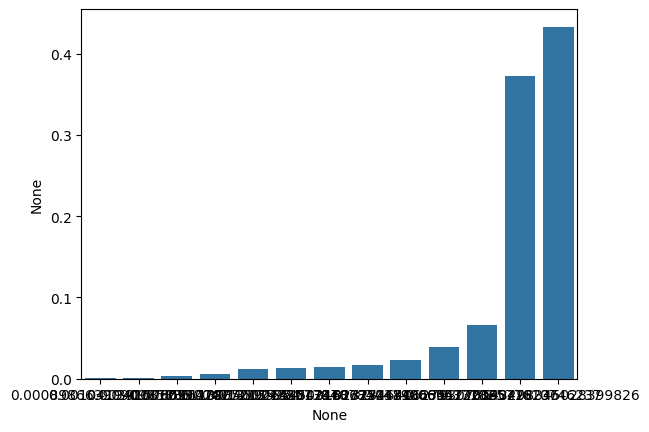

In [21]:
import seaborn as sns
%matplotlib inline

rf_reg = RandomForestRegressor(n_estimators=1000)

#앞 예제에서 만들어진 X_data, y_target 데이터 세트를 적용해 학습
rf_reg.fit(X_data, y_target)

feature_series = pd.Series(data=rf_reg.feature_importances_, index=X_data.columns)
feature_series = feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y=feature_series)

### 회귀 트리와 선형 회귀의 예측값 비교
- 회귀 트리 Regressor가 어떻게 예측값을 판단하는지 선형 회귀와 비교해 시각화
- 보스턴 데이터 세트에서 RM 피처 하나만 이용하고 100개의 데이터만 샘플링
- LinearRegression과 결정 트리의 max_depth를 2, 7로 해서 학습

(100, 2)


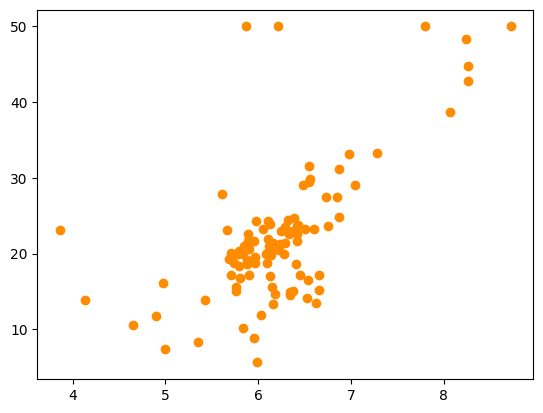

In [22]:
bostonDF = X_data.copy()
bostonDF['PRICE'] = y_target

bostonDF_sample=bostonDF[['RM','PRICE']]
bostonDF_sample=bostonDF_sample.sample(n=100,random_state=0)
print(bostonDF_sample.shape)
plt.figure()
plt.scatter(bostonDF_sample.RM,bostonDF_sample.PRICE,c='darkorange')


In [24]:
import numpy as np
from sklearn.linear_model import LinearRegression

#선형 회귀와 결정 트리 기반의 Regressor 생성, DecisionTreeRegressor의 max_depth는 각각 2,7
lr_reg=LinearRegression()
rf_reg2=DecisionTreeRegressor(max_depth=2)
rf_reg7=DecisionTreeRegressor(max_depth=7)

#실제 예측을 적용할 테스트용 데이터 세트를 4.5~8.5까지의 100개 데이터 세트로 생성
X_test = np.arange(4.5, 8.5, 0.04).reshape(-1, 1)

# 보스턴 주택 가격 데이터에서 시각화를 위해 피처는 RM만 그리고 결정 데이터인 PRICE 추출
X_feature=bostonDF_sample['RM'].values.reshape(-1,1)
y_target=bostonDF_sample['PRICE'].values.reshape(-1,1)

#학습과 예측 수행
lr_reg.fit(X_feature,y_target)
rf_reg2.fit(X_feature,y_target)
rf_reg7.fit(X_feature,y_target)

pred_lr=lr_reg.predict(X_test)
pred_rf2=rf_reg2.predict(X_test)
pred_rf7=rf_reg7.predict(X_test)

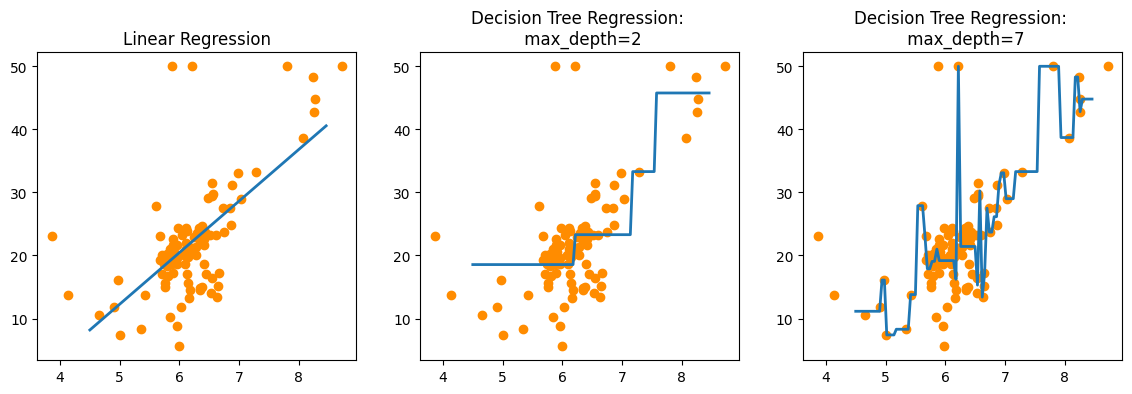

In [25]:
fig, (ax1,ax2,ax3)=plt.subplots(figsize=(14,4),ncols=3)

#X축 값을 4.5~8.5로 변환하며 입력했을 때 선형 회귀와 결정 트리 회귀 예측선 시각화
#선형 회귀로 학습된 모델 회귀 예측선
ax1.set_title('Linear Regression')
ax1.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c='darkorange')
ax1.plot(X_test,pred_lr,label='linear',linewidth=2)

#DecisionTreeRegressor의 max_depth를 2로 했을 때 회귀 예측선
ax2.set_title('Decision Tree Regression: \n max_depth=2')
ax2.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c='darkorange')
ax2.plot(X_test,pred_rf2, label="max_depth:3", linewidth=2)

#DecisionTreeRegressor의 max_depth를 7로 했을 때 회귀 예측선
ax3.set_title('Decision Tree Regression: \n max_depth=7')
ax3.scatter(bostonDF_sample.RM, bostonDF_sample.PRICE, c='darkorange')
ax3.plot(X_test,pred_rf7, label="max_depth:7", linewidth=2)

- 선형 회귀는 직선으로 예측 회귀선을 표현
- 회귀 트리는 분할되는 데이터 지점에 따라 브랜치를 만들면서 계단 형태로 회귀선을 만듦
- max_depth=7인 경우에는 학습 데이터 세트의 이상치(outlier) 데이터도 학습하면서 복잡한 계단 형태의 회귀선을 만들어 과적합이 되기 쉬운 모델이 됨